# Kernel density estimation

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.datasets import fetch_species_distributions
from sklearn.neighbors import KernelDensity
from sklearn.model_selection import GridSearchCV
from ipywidgets import interact, FloatLogSlider, Dropdown

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
fill_color  = '#cfe8f3'
true_color  = '#333333'

## The data

A sample of a mixture of two normal distributions: 30% of the observations come from a $N(0,1)$ and 70% from a $N(5,1)$. Since we simulate the data, we know the true density and we can compare the estimators with it.

In [3]:
def make_data(N, f=0.3, seed=1):
    rng = np.random.default_rng(seed)
    x = rng.normal(size=N)   # normal random numbers
    x[int(f * N):] += 5      # add 5 to the last (1-f)*N numbers
    return x

def true_density(x_grid, f=0.3):
    return f*norm.pdf(x_grid) + (1-f)*norm.pdf(x_grid, loc=5)

In [4]:
N = 1000
x = make_data(N)

x_grid = np.linspace(-4, 9, 1000)

## The histogram

The histogram is a density estimator: with `density=True` the heights are such that the total area is one.

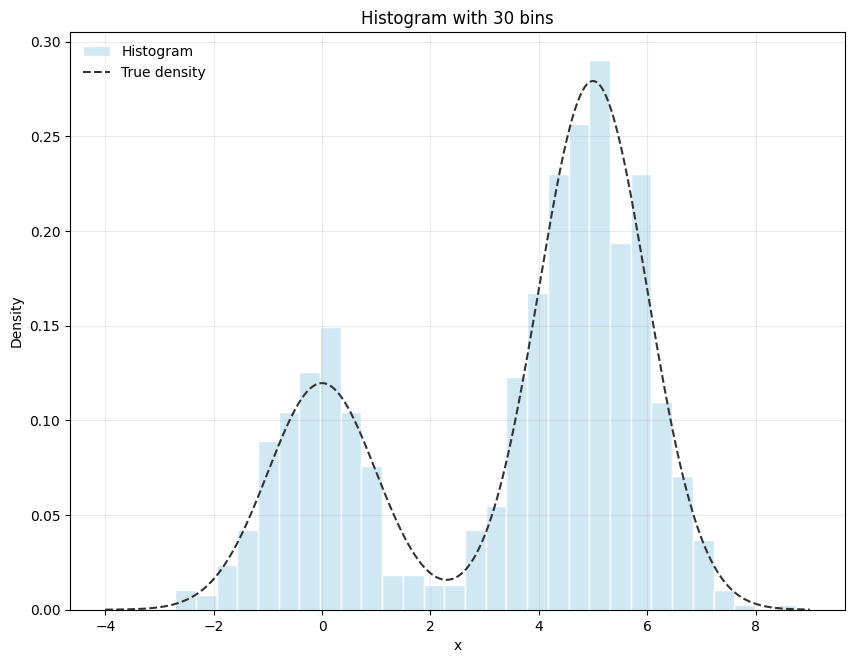

In [5]:
fig, ax = plt.subplots(figsize=(10, 7.5))
density, bins, patches = ax.hist(x, bins=30, density=True, color=fill_color, edgecolor='white', linewidth=1,
                                 label='Histogram')
ax.plot(x_grid, true_density(x_grid), '--', color=true_color, lw=1.5, label='True density')
ax.set_xlabel('x')
ax.set_ylabel('Density')
ax.set_title('Histogram with 30 bins')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

In [6]:
widths = bins[1:] - bins[:-1]
print('Width of the bins:', widths[0])
print('Total area:       ', (density * widths).sum())

Width of the bins: 0.38209734682337126
Total area:        1.0


The histogram depends on the number of bins (and on where they start), and it is not smooth.

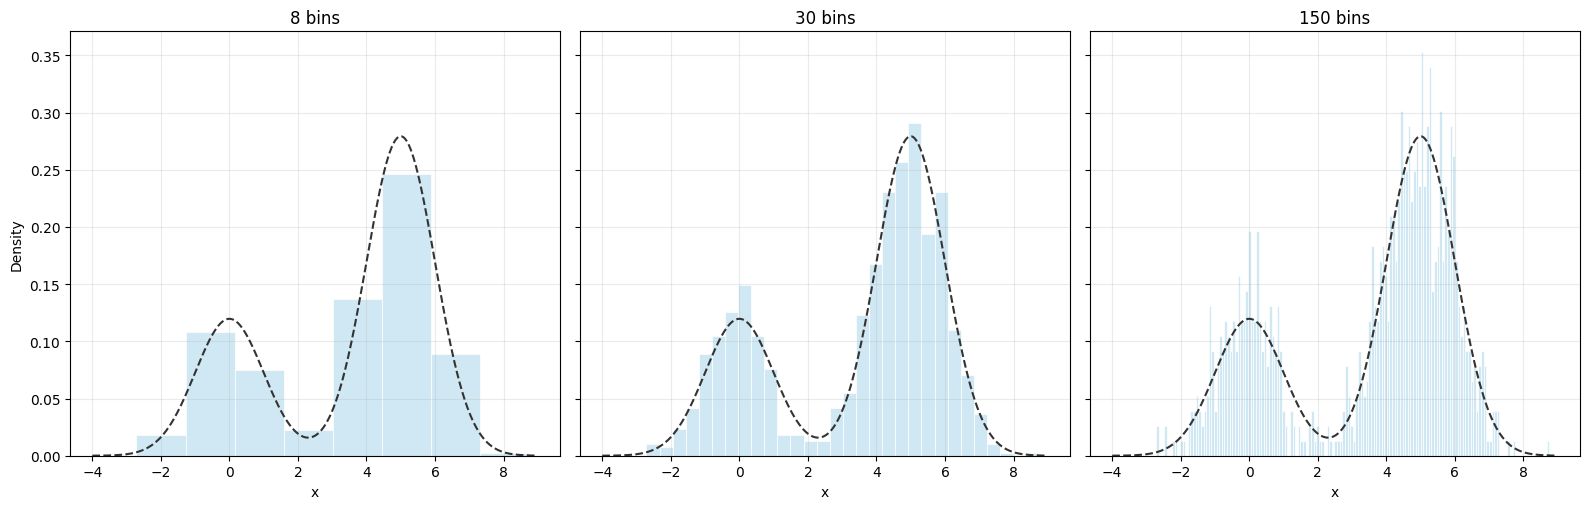

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharey=True)
for ax, n_bins in zip(axes, [8, 30, 150]):
    ax.hist(x, bins=n_bins, density=True, color=fill_color, edgecolor='white', linewidth=0.5)
    ax.plot(x_grid, true_density(x_grid), '--', color=true_color, lw=1.5)
    ax.set_xlabel('x')
    ax.set_title(f'{n_bins} bins')
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('Density')
plt.tight_layout()

## Kernel density estimator by hand

Instead of counting the observations in fixed bins, we put a small density (the kernel $K$) centered at each observation and average them,
$$\hat f(x) = \frac{1}{nh}\sum_{i=1}^n K\left(\frac{x-x_i}{h}\right).$$
With the Gaussian kernel, each observation contributes a $N(x_i, h^2)$ density divided by $n$. With only 8 observations we can see the sum:

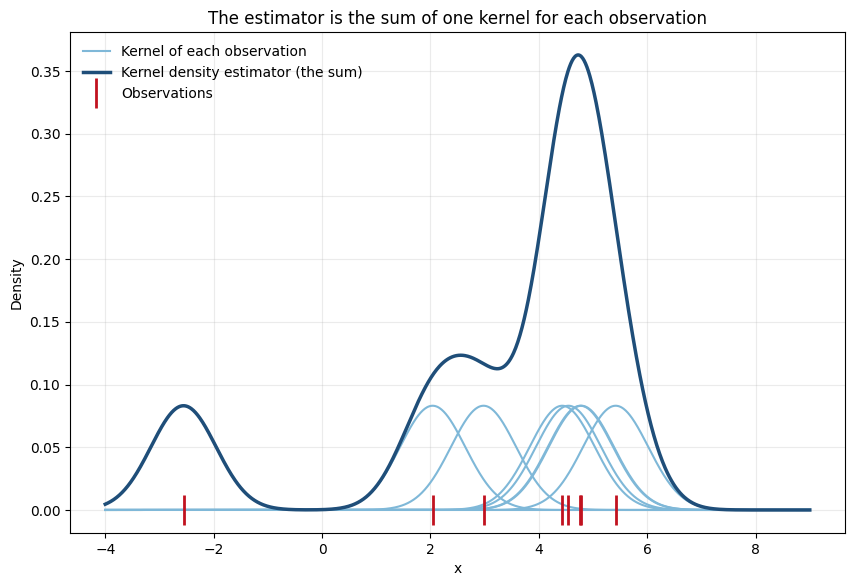

In [8]:
x_small = make_data(8, seed=3)
h_small = 0.6
bumps = norm.pdf((x_grid[:, None]-x_small[None, :])/h_small)/(len(x_small)*h_small)

fig, ax = plt.subplots(figsize=(10, 6.5))
for i in range(len(x_small)):
    ax.plot(x_grid, bumps[:, i], color='#7fb8d8', lw=1.5, label='Kernel of each observation' if i == 0 else None)
ax.plot(x_grid, bumps.sum(axis=1), color=line_color, lw=2.5, label='Kernel density estimator (the sum)')
ax.plot(x_small, np.zeros(len(x_small)), '|', color=point_color, markersize=22, markeredgewidth=2, label='Observations')
ax.set_xlabel('x')
ax.set_ylabel('Density')
ax.set_title('The estimator is the sum of one kernel for each observation')
ax.legend(loc='upper left', frameon=False)
ax.grid(True, alpha=0.25)

### The bandwidth

For the bandwidth $h$, the rule of thumb of Silverman (optimal if the data are normal) is $h^* = 1.06\,\hat\sigma\,n^{-1/5}$.

In [9]:
h_star = 1.06*np.std(x)/(N**(1/5))
print('h_star:', h_star)

h_star: 0.6719181013708483


In [10]:
def kde_by_hand(x_grid, x, h):
    return norm.pdf((x_grid[:, None]-x[None, :])/h).sum(axis=1)/(len(x)*h)

density = kde_by_hand(x_grid, x, h_star)

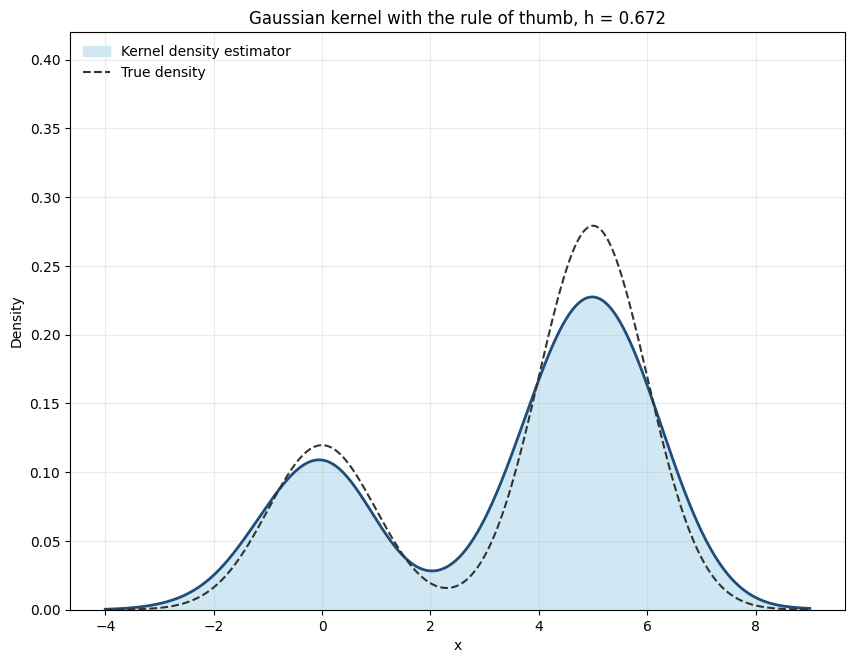

In [11]:
def plot_density(ax, density, title, legend=True):
    ax.fill_between(x_grid, density, color=fill_color, label='Kernel density estimator')
    ax.plot(x_grid, density, color=line_color, lw=2)
    ax.plot(x_grid, true_density(x_grid), '--', color=true_color, lw=1.5, label='True density')
    ax.set_xlabel('x')
    ax.set_ylabel('Density')
    ax.set_ylim(0, 0.42)
    ax.set_title(title)
    ax.grid(True, alpha=0.25)
    if legend:
        ax.legend(loc='upper left', frameon=False)

fig, ax = plt.subplots(figsize=(10, 7.5))
plot_density(ax, density, f'Gaussian kernel with the rule of thumb, h = {h_star:.3f}')

The rule of thumb gives a bandwidth that is too large here: the data are far from normal, and the estimator is lower than the true density at the two modes.

## Using KernelDensity

In [12]:
# instantiate and fit the KDE model
kde = KernelDensity(bandwidth=h_star, kernel='gaussian')
kde.fit(x[:, None])

# score_samples returns the log of the probability density
logprob = kde.score_samples(x_grid[:, None])

print('Largest difference with the estimator by hand:', np.max(np.abs(np.exp(logprob) - density)))

Largest difference with the estimator by hand: 8.631984016460592e-15


### Choosing the bandwidth by cross-validation

We choose the bandwidth that maximizes the log-likelihood of the observations left out (5-fold cross-validation).

In [13]:
params = {'bandwidth': np.logspace(-1.5, 0.5, 100)}
grid = GridSearchCV(KernelDensity(), params)
grid.fit(x[:, None])

h_cv = grid.best_params_['bandwidth']
print('Bandwidth chosen by cross-validation:', h_cv)

Bandwidth chosen by cross-validation: 0.3552262494616665


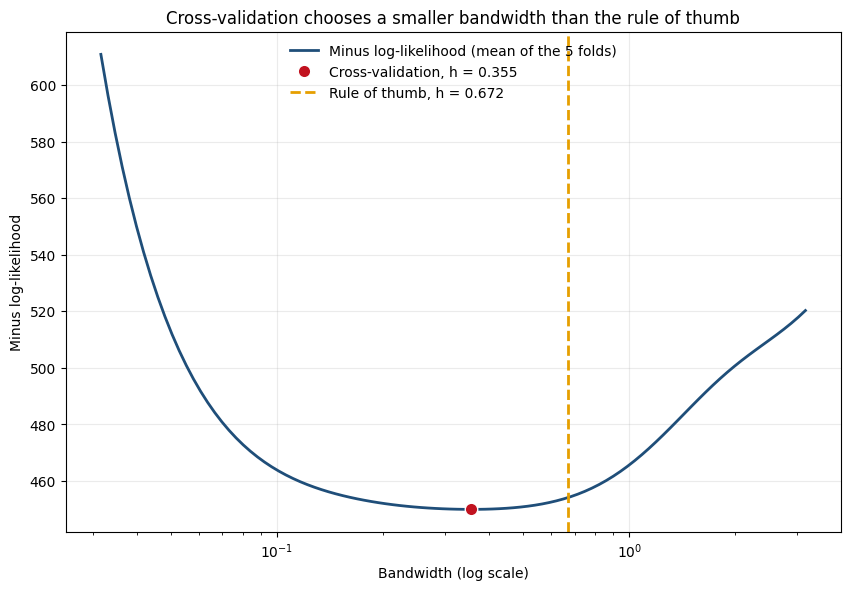

In [14]:
scores = -grid.cv_results_['mean_test_score']

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.plot(params['bandwidth'], scores, color=line_color, lw=2, label='Minus log-likelihood (mean of the 5 folds)')
ax.plot(h_cv, scores.min(), 'o', color=point_color, markersize=9, markeredgecolor='white', markeredgewidth=1,
        label=f'Cross-validation, h = {h_cv:.3f}')
ax.axvline(h_star, ls='--', color='#E69F00', lw=2, label=f'Rule of thumb, h = {h_star:.3f}')
ax.set_xscale('log')
ax.set_xlabel('Bandwidth (log scale)')
ax.set_ylabel('Minus log-likelihood')
ax.set_title('Cross-validation chooses a smaller bandwidth than the rule of thumb')
ax.legend(loc='upper center', frameon=False)
ax.grid(True, alpha=0.25)

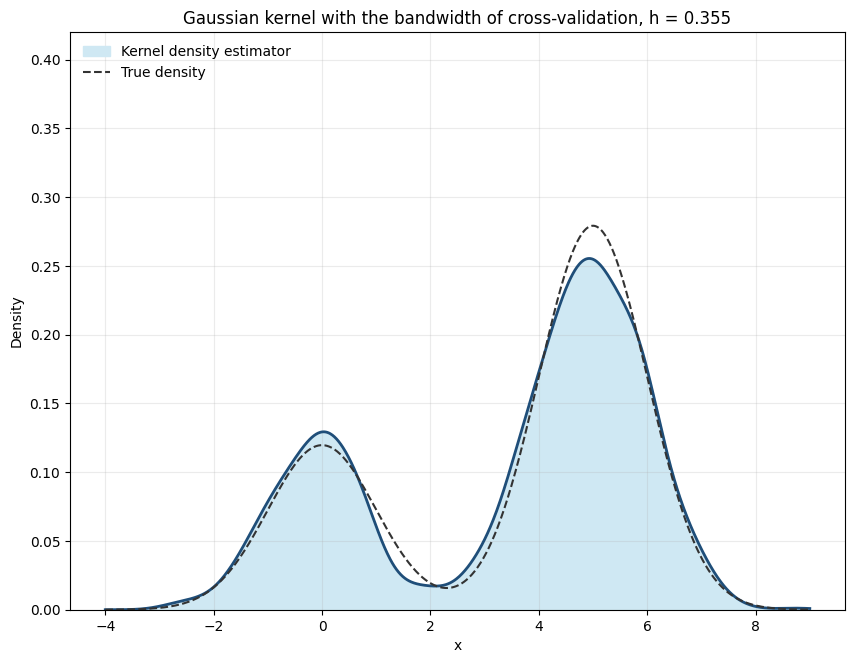

In [15]:
fig, ax = plt.subplots(figsize=(10, 7.5))
plot_density(ax, kde_by_hand(x_grid, x, h_cv), f'Gaussian kernel with the bandwidth of cross-validation, h = {h_cv:.3f}')

## The effect of the bandwidth and the kernel

Move the slider to change the bandwidth, and choose another kernel (this cell needs a running kernel). The bandwidth matters much more than the kernel.

In [16]:
def density_sklearn(h, kernel):
    kde = KernelDensity(bandwidth=h, kernel=kernel).fit(x[:, None])
    return np.exp(kde.score_samples(x_grid[:, None]))

def interactive_kde(h, kernel):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    plot_density(ax, density_sklearn(h, kernel), f'{kernel} kernel, h = {h:.3f}')
    plt.show()

interact(interactive_kde,
         h=FloatLogSlider(value=h_cv, base=10, min=-1.5, max=0.5, step=0.02, description='h'),
         kernel=Dropdown(options=['gaussian', 'tophat', 'epanechnikov', 'exponential', 'linear', 'cosine'], description='kernel'));

interactive(children=(FloatLogSlider(value=0.3552262494616665, description='h', max=0.5, min=-1.5, step=0.02),…

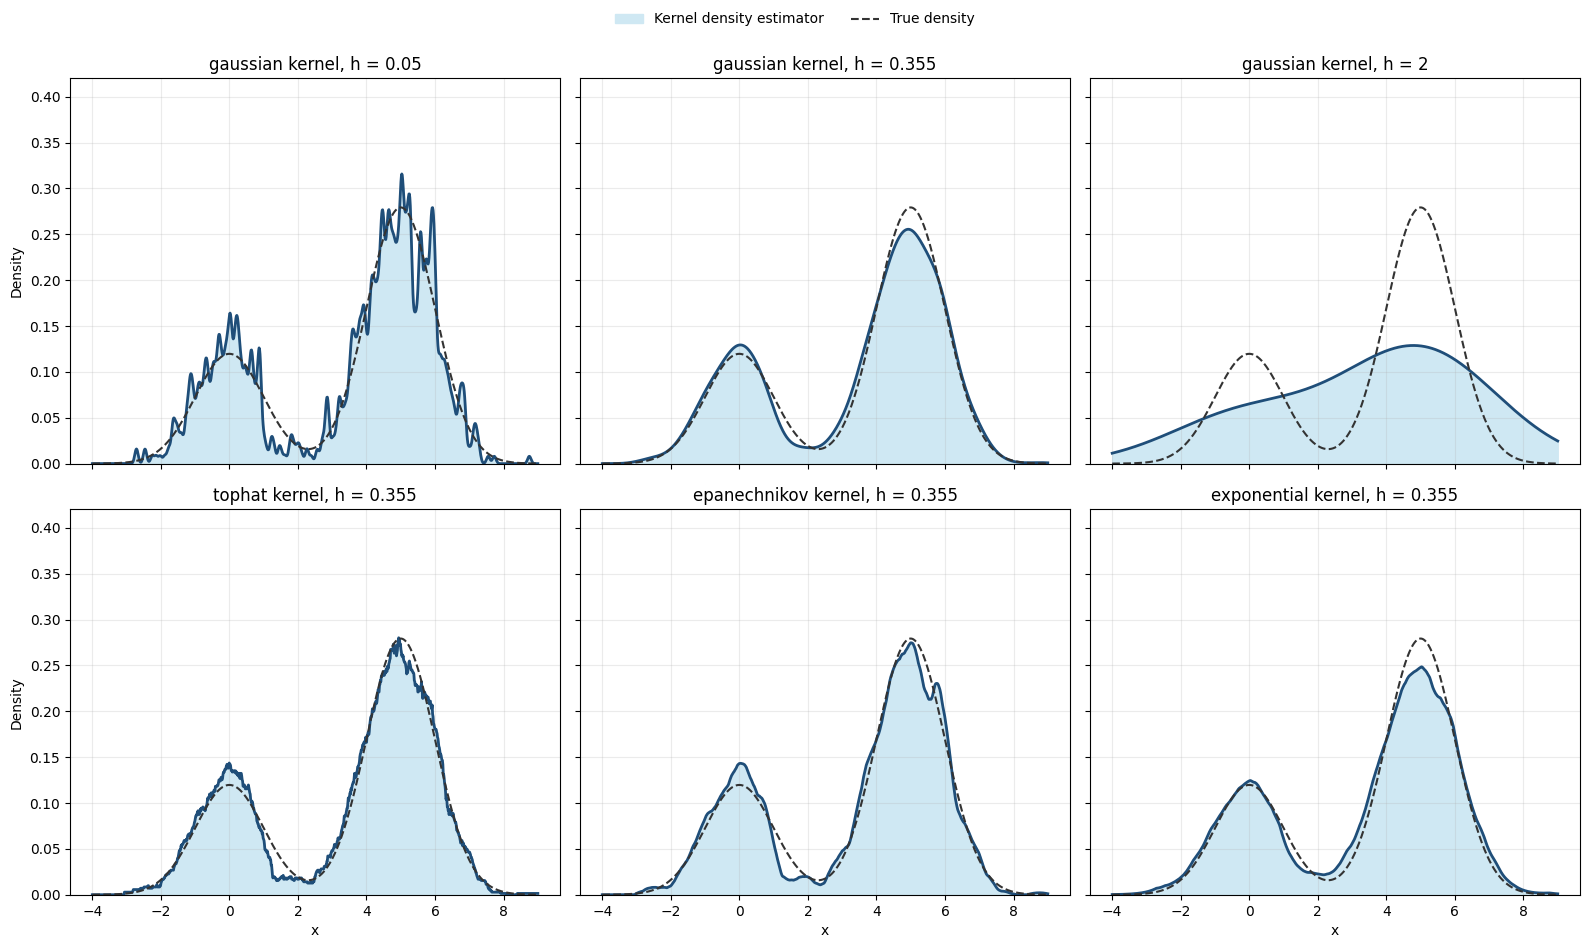

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9.5), sharex=True, sharey=True)
for ax, h in zip(axes[0], [0.05, h_cv, 2]):
    plot_density(ax, density_sklearn(h, 'gaussian'), f'gaussian kernel, h = {h:.3g}', legend=False)
for ax, kernel in zip(axes[1], ['tophat', 'epanechnikov', 'exponential']):
    plot_density(ax, density_sklearn(h_cv, kernel), f'{kernel} kernel, h = {h_cv:.3g}', legend=False)
for ax in axes[0]:
    ax.set_xlabel('')
for ax in axes[:, 1:].ravel():
    ax.set_ylabel('')
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.96))

## Example in two dimensions: distribution of two species

Example of the documentation of `sklearn`: places of South America where two species were observed, the brown-throated sloth (*Bradypus variegatus*) and the forest small rice rat (*Microryzomys minutus*). The kernel density estimator, with the distance on the sphere (`haversine`), gives a map of where each species lives.

`fetch_species_distributions` downloads the data the first time it is called (it needs internet once).

In [18]:
def construct_grids(batch):
    # Construct the map grid from the object returned by fetch_species_distributions
    # x,y coordinates for corner cells
    xmin = batch.x_left_lower_corner + batch.grid_size
    xmax = xmin + (batch.Nx * batch.grid_size)
    ymin = batch.y_left_lower_corner + batch.grid_size
    ymax = ymin + (batch.Ny * batch.grid_size)

    # x coordinates of the grid cells
    xgrid = np.arange(xmin, xmax, batch.grid_size)
    # y coordinates of the grid cells
    ygrid = np.arange(ymin, ymax, batch.grid_size)

    return (xgrid, ygrid)

In [19]:
# Get matrices/arrays of species IDs and locations
data = fetch_species_distributions()
species_names = ['Bradypus variegatus', 'Microryzomys minutus']

Xtrain = np.vstack([data['train']['dd lat'], data['train']['dd long']]).T
ytrain = np.array([d.decode('ascii').startswith('micro') for d in data['train']['species']], dtype='int')
Xtrain *= np.pi / 180.  # Convert lat/long to radians

# Set up the data grid for the contour plot
xgrid, ygrid = construct_grids(data)
X, Y = np.meshgrid(xgrid[::5], ygrid[::5][::-1])
land_reference = data.coverages[6][::5, ::5]
land_mask = (land_reference > -9999).ravel()

xy = np.vstack([Y.ravel(), X.ravel()]).T
xy = xy[land_mask]
xy *= np.pi / 180.

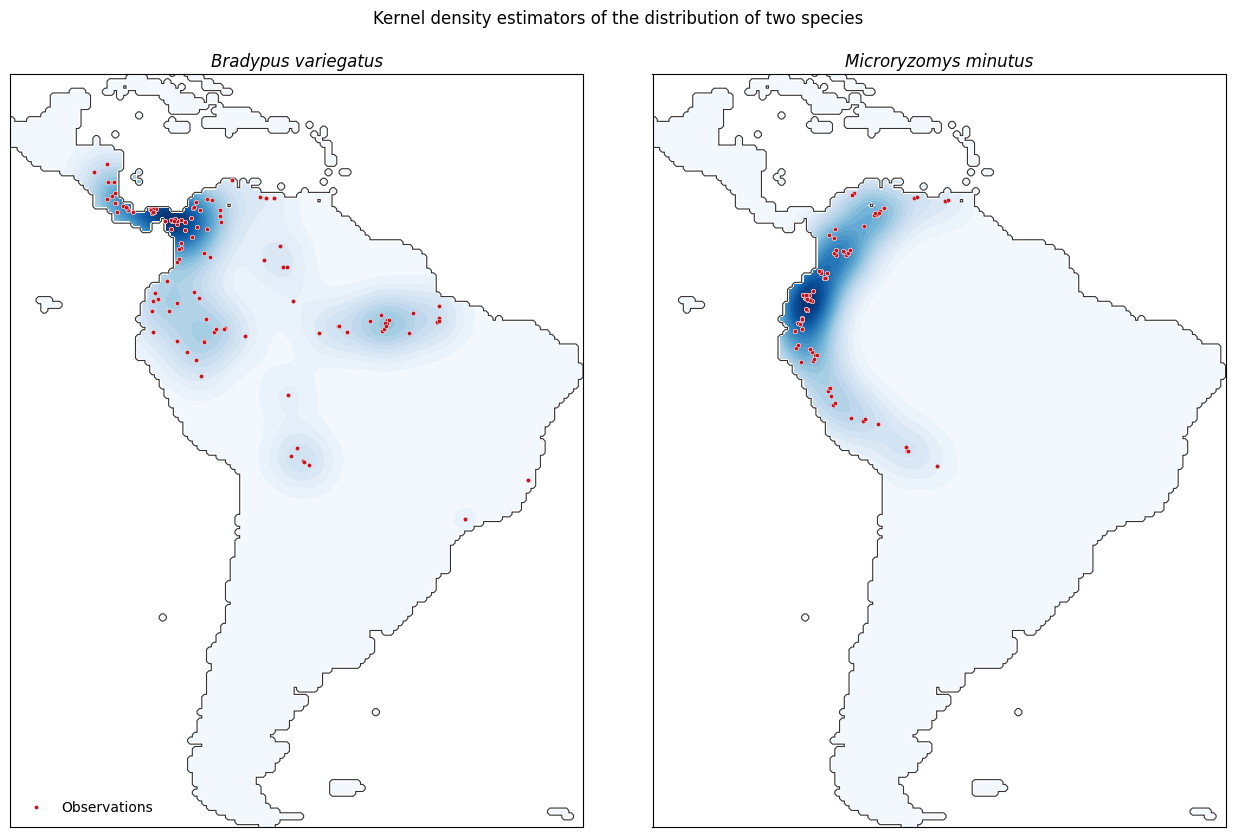

In [20]:
# Plot map of South America with distributions of each species
fig, axes = plt.subplots(1, 2, figsize=(13, 8.5))

for i, ax in enumerate(axes):
    # construct a kernel density estimate of the distribution, in spherical coordinates
    kde = KernelDensity(bandwidth=0.04, metric='haversine', kernel='gaussian', algorithm='ball_tree')
    kde.fit(Xtrain[ytrain == i])

    # evaluate only on the land: the ocean is left empty
    Z = np.full(land_mask.shape[0], np.nan)
    Z[land_mask] = np.exp(kde.score_samples(xy))
    Z = Z.reshape(X.shape)

    # plot contours of the density
    levels = np.linspace(0, np.nanmax(Z), 25)
    ax.contourf(X, Y, Z, levels=levels, cmap='Blues')

    # coastlines from the land coverage
    ax.contour(X, Y, land_reference, levels=[-9998], colors='#333333', linestyles='solid', linewidths=0.8)

    # observations
    ax.plot(Xtrain[ytrain == i, 1]*180/np.pi, Xtrain[ytrain == i, 0]*180/np.pi, 'o', color=point_color, markersize=3,
            markeredgecolor='white', markeredgewidth=0.3, label='Observations')
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(species_names[i], style='italic')
axes[0].legend(loc='lower left', frameon=False)
fig.suptitle('Kernel density estimators of the distribution of two species')
fig.tight_layout(rect=(0, 0, 1, 0.96))